# Modell-Erklärbarkeit

In diesem Notebook werden die final ausgewählten Versicherungsmodelle nach Abschluss der Modellselektion interpretiert.

Der Schwerpunkt liegt auf der Frage, welche Merkmale die prognostizierte Schadenfrequenz, Schadenhöhe und Pure Premium beeinflussen. Dazu werden GLM-Koeffizienten, Feature Importances sowie Partial-Dependence- und ICE-Analysen verwendet.

Die Explainability-Analysen verändern die bereits festgelegten Modelle nicht und werden ausschließlich zur fachlichen Interpretation verwendet.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from joblib import load

In [3]:
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

CURATED_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "policy_curated.pq"
)

SPLIT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "policy_train_test_split.pq"
)

FREQUENCY_MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "frequency_poisson_quantile_spline_holdout_v2.joblib"
)

SEVERITY_MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "severity_gamma_spline_scaled_holdout_v2.joblib"
)

TWEEDIE_MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "tweedie_direct_pure_premium_holdout_v1.joblib"
)

print("Project root:", PROJECT_ROOT)
print("Curated data:", CURATED_PATH.exists())
print("Split:", SPLIT_PATH.exists())
print("Frequency model:", FREQUENCY_MODEL_PATH.exists())
print("Severity model:", SEVERITY_MODEL_PATH.exists())
print("Tweedie model:", TWEEDIE_MODEL_PATH.exists())

Project root: C:\Users\Mesut\Desktop\kfz-insurance-risk-platform
Curated data: True
Split: True
Frequency model: True
Severity model: True
Tweedie model: True


## Analysegrundlage

Für die Explainability-Analyse werden die bereits finalisierten Holdout-Modelle verwendet.

Die Analysepopulationen entsprechen den jeweiligen Modelluniversen:

- Das Frequency-Modell wird auf allen Policen des kanonischen Holdouts analysiert.
- Das Severity-Modell wird ausschließlich auf Policen mit beobachtbarer und konsistenter positiver Schadenhöhe analysiert.
- Das Tweedie-Modell wird auf dem zuvor definierten beobachtbaren Schadenuniversum des Holdouts analysiert.

Damit bleibt die fachliche Definition der einzelnen Modelle auch in der Interpretationsphase unverändert.

In [4]:
curated_df = pd.read_parquet(
    CURATED_PATH
)

split_df = pd.read_parquet(
    SPLIT_PATH
)

model_df = curated_df.merge(
    split_df,
    on="IDpol",
    how="left",
    validate="one_to_one",
)

frequency_model = load(
    FREQUENCY_MODEL_PATH
)

severity_model = load(
    SEVERITY_MODEL_PATH
)

tweedie_model = load(
    TWEEDIE_MODEL_PATH
)


# Frequency holdout universe
frequency_test_df = model_df.loc[
    model_df["split"] == "test"
].copy()


# Severity holdout universe
severity_test_mask = (
    (model_df["split"] == "test")
    & (model_df["ClaimNb"] > 0)
    & model_df["total_claim_amount"].notna()
    & (model_df["total_claim_amount"] > 0)
    & (~model_df["missing_severity"])
    & (~model_df["claim_count_mismatch"])
)

severity_test_df = model_df.loc[
    severity_test_mask
].copy()


# Tweedie observable holdout universe
tweedie_test_mask = (
    (model_df["split"] == "test")
    & model_df["total_claim_amount"].notna()
    & (~model_df["claim_count_mismatch"])
    & (model_df["Exposure"] > 0)
    & (model_df["total_claim_amount"] >= 0)
)

tweedie_test_df = model_df.loc[
    tweedie_test_mask
].copy()


print("Merged rows:", len(model_df))
print(
    "Missing split:",
    model_df["split"].isna().sum(),
)

print(
    "\nFrequency holdout rows:",
    len(frequency_test_df),
)

print(
    "Severity holdout rows:",
    len(severity_test_df),
)

print(
    "Tweedie holdout rows:",
    len(tweedie_test_df),
)

print(
    "\nFrequency model:",
    type(frequency_model).__name__,
)

print(
    "Severity model:",
    type(severity_model).__name__,
)

print(
    "Tweedie model:",
    type(tweedie_model).__name__,
)

Merged rows: 678013
Missing split: 0

Frequency holdout rows: 135603
Severity holdout rows: 4999
Tweedie holdout rows: 133790

Frequency model: Pipeline
Severity model: Pipeline
Tweedie model: Pipeline


In [5]:
def show_model_features(name, model):
    preprocessor = model.named_steps["preprocessor"]

    print(f"\n{name}")

    for transformer_name, transformer, columns in preprocessor.transformers_:
        if transformer_name == "remainder":
            continue

        print(
            f"{transformer_name}:",
            list(columns),
        )


show_model_features(
    "Frequency v2",
    frequency_model,
)

show_model_features(
    "Severity v2",
    severity_model,
)

show_model_features(
    "Tweedie v1",
    tweedie_model,
)


Frequency v2
categorical: ['VehPower', 'VehBrand', 'VehGas', 'Region']
spline: ['DrivAge', 'VehAge', 'BonusMalus']
numeric: ['log_density']

Severity v2
categorical: ['VehPower', 'VehBrand', 'VehGas', 'Region']
spline: ['DrivAge', 'VehAge', 'BonusMalus']
numeric: ['log_density']

Tweedie v1
categorical: ['VehPower', 'VehBrand', 'VehGas', 'Region']
spline: ['DrivAge', 'VehAge', 'BonusMalus']
numeric: ['log_density']


## GLM-Koeffizienten

Da alle drei finalen Modelle auf Generalized Linear Models mit Log-Link basieren, werden ergänzend die geschätzten Modellkoeffizienten betrachtet.

Die Koeffizienten beziehen sich auf die nach dem Preprocessing erzeugten Modellmerkmale. Bei kategorialen Variablen beschreiben sie den Effekt relativ zur jeweiligen Referenzkategorie. Bei den numerischen Variablen werden Spline-Basisfunktionen verwendet; einzelne Spline-Koeffizienten dürfen daher nicht als direkter linearer Effekt des ursprünglichen Merkmals interpretiert werden.

Die Koeffizienten dienen deshalb vor allem zur transparenten Dokumentation der Modellstruktur. Für die inhaltliche Interpretation der numerischen Wirkungsverläufe werden anschließend Permutation Importance sowie PDP- und ICE-Analysen verwendet.

In [6]:
def extract_glm_coefficients(name, pipeline):
    preprocessor = pipeline.named_steps["preprocessor"]
    glm_model = pipeline.named_steps["model"]

    feature_names = preprocessor.get_feature_names_out()
    coefficients = np.asarray(glm_model.coef_).ravel()

    coefficient_df = pd.DataFrame({
        "feature": feature_names,
        "coefficient": coefficients,
    })

    coefficient_df["abs_coefficient"] = (
        coefficient_df["coefficient"].abs()
    )

    coefficient_df = coefficient_df.sort_values(
        "abs_coefficient",
        ascending=False,
    ).reset_index(drop=True)

    print(f"\n{name}")
    print(f"Intercept: {float(glm_model.intercept_):.6f}")

    display(
        coefficient_df.head(15)
    )

    return coefficient_df


frequency_coefficients = extract_glm_coefficients(
    "Frequency v2",
    frequency_model,
)

severity_coefficients = extract_glm_coefficients(
    "Severity v2",
    severity_model,
)

tweedie_coefficients = extract_glm_coefficients(
    "Tweedie v1",
    tweedie_model,
)


Frequency v2
Intercept: -2.175974


,feature,coefficient,abs_coefficient
0,spline__VehAge_sp_0,2.386374,2.386374
1,spline__BonusMalus_sp_7,2.071153,2.071153
2,spline__VehAge_sp_7,-1.844484,1.844484
3,spline__DrivAge_sp_0,1.281016,1.281016
4,spline__BonusMalus_sp_4,-0.946197,0.946197
5,spline__BonusMalus_sp_3,-0.819719,0.819719
6,spline__DrivAge_sp_1,-0.645756,0.645756
7,spline__DrivAge_sp_2,-0.395858,0.395858
8,spline__BonusMalus_sp_6,-0.373191,0.373191
9,categorical__Region_R21,0.291082,0.291082



Severity v2
Intercept: 7.631870


,feature,coefficient,abs_coefficient
0,spline__DrivAge_sp_0,0.152899,0.152899
1,spline__DrivAge_sp_1,0.034261,0.034261
2,spline__BonusMalus_sp_3,0.033291,0.033291
3,spline__DrivAge_sp_3,-0.030950,0.030950
4,categorical__VehPower_5,-0.029880,0.029880
5,categorical__Region_R24,0.028251,0.028251
6,spline__DrivAge_sp_2,-0.024141,0.024141
7,categorical__VehPower_9,0.020138,0.020138
8,spline__BonusMalus_sp_4,-0.020136,0.020136
9,categorical__VehBrand_B11,0.019030,0.019030



Tweedie v1
Intercept: 3.498707


,feature,coefficient,abs_coefficient
0,spline__DrivAge_sp_0,8.627408,8.627408
1,spline__VehAge_sp_7,-3.989382,3.989382
2,spline__DrivAge_sp_7,2.997352,2.997352
3,spline__DrivAge_sp_5,2.529548,2.529548
4,spline__DrivAge_sp_4,2.281749,2.281749
5,spline__DrivAge_sp_6,2.243684,2.243684
6,spline__DrivAge_sp_3,2.109622,2.109622
7,spline__DrivAge_sp_2,2.039858,2.039858
8,spline__BonusMalus_sp_3,-1.804623,1.804623
9,spline__BonusMalus_sp_7,1.734005,1.734005


### Ergebnis – GLM-Koeffizienten

Die Koeffizienten bestätigen, dass die numerischen Risikomerkmale in den finalen GLM-Strukturen überwiegend über nichtlineare Spline-Komponenten abgebildet werden.

Im Frequency-Modell treten insbesondere Spline-Komponenten von `VehAge`, `BonusMalus` und `DrivAge` mit größeren absoluten Koeffizienten hervor. Zusätzlich zeigen einzelne Kategorien von `Region` und `VehPower` relevante Abweichungen gegenüber ihren jeweiligen Referenzkategorien.

Beim Severity-Modell sind die geschätzten Koeffizienten insgesamt deutlich kleiner. Dies passt zur bereits beobachteten schwächeren und instabileren Prognosestruktur dieses Modells.

Im Tweedie-Modell weisen insbesondere Spline-Komponenten von `DrivAge`, `VehAge` und `BonusMalus` größere Koeffizienten auf. Auch einzelne regionale Kategorien tragen zur Modellstruktur bei.

Die absoluten Koeffizientenwerte dürfen jedoch nicht direkt als Feature Importance oder zwischen den Modellen verglichen werden. Aufgrund der Spline-Transformationen, unterschiedlichen Modellskalierungen und Zielgrößen beschreibt ein einzelner Koeffizient nicht den vollständigen Effekt eines ursprünglichen Merkmals. Die globale Bedeutung und Wirkungsrichtung werden deshalb ergänzend mit Permutation Importance sowie PDP- und ICE-Analysen bewertet.

## Globale Feature Importance

Zur globalen Interpretation wird eine devianzbasierte Permutationsimportance verwendet.

Dabei wird jeweils ein Eingangsmerkmal im Holdout-Datensatz zufällig permutiert und anschließend gemessen, wie stark sich die Modellgüte verschlechtert. Ein größerer positiver Wert bedeutet, dass das Modell stärker auf die Information dieses Merkmals angewiesen ist.

Für jedes Modell wird dabei dieselbe Zieldefinition und Gewichtungslogik wie bei der ursprünglichen Modellbewertung beibehalten.

In [7]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    mean_poisson_deviance,
    make_scorer,
)

frequency_features = [
    "VehPower",
    "VehBrand",
    "VehGas",
    "Region",
    "DrivAge",
    "VehAge",
    "BonusMalus",
    "log_density",
]

X_frequency_test = frequency_test_df[
    frequency_features
].copy()

y_frequency_test = (
    frequency_test_df["ClaimNb"]
    / frequency_test_df["Exposure"]
)

w_frequency_test = frequency_test_df[
    "Exposure"
]

poisson_scorer = make_scorer(
    mean_poisson_deviance,
    greater_is_better=False,
)

frequency_perm = permutation_importance(
    frequency_model,
    X_frequency_test,
    y_frequency_test,
    scoring=poisson_scorer,
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
    sample_weight=w_frequency_test,
)

frequency_importance = (
    pd.DataFrame({
        "feature": frequency_features,
        "importance_mean": frequency_perm.importances_mean,
        "importance_std": frequency_perm.importances_std,
    })
    .sort_values(
        "importance_mean",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(frequency_importance)

,feature,importance_mean,importance_std
0,BonusMalus,0.037762,0.000856
1,VehAge,0.032071,0.000694
2,DrivAge,0.007280,0.000581
3,VehPower,0.001956,0.000304
4,log_density,0.001432,0.000155
5,Region,0.001145,0.000244
6,VehBrand,0.000896,0.000127
7,VehGas,0.000324,0.000065


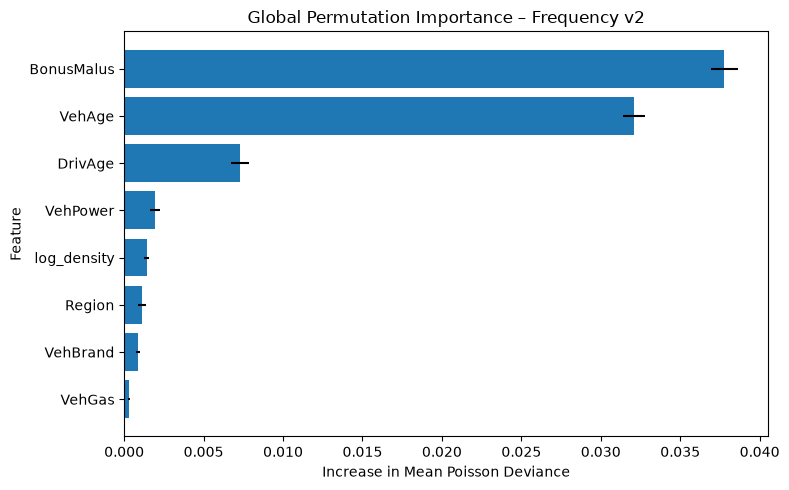

In [8]:
plt.figure(figsize=(8, 5))

plt.barh(
    frequency_importance["feature"][::-1],
    frequency_importance["importance_mean"][::-1],
    xerr=frequency_importance["importance_std"][::-1],
)

plt.xlabel("Increase in Mean Poisson Deviance")
plt.ylabel("Feature")
plt.title("Global Permutation Importance – Frequency v2")
plt.tight_layout()
plt.show()

### Ergebnis – Frequency-Modell

Die Permutationsimportance zeigt, dass `BonusMalus` und `VehAge` die wichtigsten globalen Einflussgrößen des finalen Frequency-Modells sind. Die Permutation dieser Merkmale führt mit Abstand zur stärksten Verschlechterung der Poisson-Deviance.

`DrivAge` besitzt ebenfalls einen klaren, jedoch deutlich kleineren Beitrag. Die übrigen Merkmale tragen zusätzlich zur Prognose bei, zeigen im globalen Holdout-Vergleich aber eine wesentlich geringere Bedeutung.

Insbesondere `VehGas` weist nur einen kleinen zusätzlichen Informationsbeitrag für die Schadenfrequenz auf.

Die Importance-Werte beschreiben den globalen Informationsbeitrag der Merkmale für die Modellgüte; sie geben noch nicht an, in welche Richtung ein Merkmal die prognostizierte Schadenfrequenz verändert.

In [9]:
from sklearn.metrics import (
    mean_gamma_deviance,
    make_scorer,
)

severity_features = [
    "VehPower",
    "VehBrand",
    "VehGas",
    "Region",
    "DrivAge",
    "VehAge",
    "BonusMalus",
    "log_density",
]

X_severity_test = severity_test_df[
    severity_features
].copy()

y_severity_test = (
    severity_test_df["total_claim_amount"]
    / severity_test_df["ClaimNb"]
)

w_severity_test = severity_test_df[
    "ClaimNb"
]

gamma_scorer = make_scorer(
    mean_gamma_deviance,
    greater_is_better=False,
)

severity_perm = permutation_importance(
    severity_model,
    X_severity_test,
    y_severity_test,
    scoring=gamma_scorer,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
    sample_weight=w_severity_test,
)

severity_importance = (
    pd.DataFrame({
        "feature": severity_features,
        "importance_mean": severity_perm.importances_mean,
        "importance_std": severity_perm.importances_std,
    })
    .sort_values(
        "importance_mean",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(severity_importance)

,feature,importance_mean,importance_std
0,DrivAge,0.002644,0.016500
1,Region,0.002444,0.001782
2,VehPower,0.001598,0.001305
3,log_density,0.000390,0.000290
4,VehBrand,-0.000580,0.000951
5,VehGas,-0.001396,0.000765
6,VehAge,-0.003879,0.002073
7,BonusMalus,-0.012693,0.006929


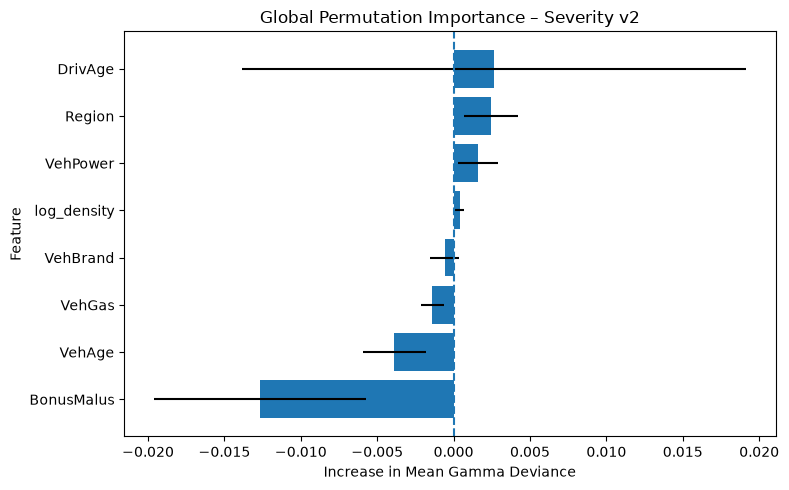

In [10]:
plt.figure(figsize=(8, 5))

plt.barh(
    severity_importance["feature"][::-1],
    severity_importance["importance_mean"][::-1],
    xerr=severity_importance["importance_std"][::-1],
)

plt.axvline(
    0,
    linestyle="--",
)

plt.xlabel("Increase in Mean Gamma Deviance")
plt.ylabel("Feature")
plt.title("Global Permutation Importance – Severity v2")
plt.tight_layout()
plt.show()

### Ergebnis – Severity-Modell

Die Permutationsimportance des Severity-Modells zeigt insgesamt nur schwache und teilweise instabile globale Merkmalseffekte.

Für `DrivAge` wird zwar der höchste mittlere Importance-Wert beobachtet, die Streuung zwischen den Wiederholungen ist jedoch deutlich größer als der Mittelwert. Eine stabile dominante Bedeutung dieses Merkmals kann daher nicht abgeleitet werden.

`Region`, `VehPower` und `log_density` zeigen kleine positive Beiträge. Mehrere Merkmale weisen leicht negative Importance-Werte auf. Dies bedeutet nicht, dass sie die Schadenhöhe inhaltlich senken, sondern dass ihre Permutation die Holdout-Deviance nicht verschlechtert beziehungsweise teilweise geringfügig verbessert.

Das Ergebnis steht im Einklang mit der bereits festgestellten begrenzten Prognose- und Rangordnungsfähigkeit des Severity-Modells. Die erklärten Einflussmuster sollten daher vorsichtig und nicht kausal interpretiert werden.

In [11]:
from sklearn.metrics import mean_tweedie_deviance

tweedie_features = [
    "VehPower",
    "VehBrand",
    "VehGas",
    "Region",
    "DrivAge",
    "VehAge",
    "BonusMalus",
    "log_density",
]

X_tweedie_test = tweedie_test_df[
    tweedie_features
].copy()

y_tweedie_test = (
    tweedie_test_df["total_claim_amount"]
    / tweedie_test_df["Exposure"]
)

w_tweedie_test = tweedie_test_df[
    "Exposure"
]

tweedie_scorer = make_scorer(
    mean_tweedie_deviance,
    greater_is_better=False,
    power=1.9,
)

tweedie_perm = permutation_importance(
    tweedie_model,
    X_tweedie_test,
    y_tweedie_test,
    scoring=tweedie_scorer,
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
    sample_weight=w_tweedie_test,
)

tweedie_importance = (
    pd.DataFrame({
        "feature": tweedie_features,
        "importance_mean": tweedie_perm.importances_mean,
        "importance_std": tweedie_perm.importances_std,
    })
    .sort_values(
        "importance_mean",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(tweedie_importance)

,feature,importance_mean,importance_std
0,BonusMalus,0.881995,0.203317
1,DrivAge,0.326726,0.205567
2,VehAge,0.135142,0.083182
3,VehGas,0.077845,0.041027
4,VehPower,0.047719,0.042692
5,log_density,0.021590,0.038430
6,Region,-0.031235,0.028607
7,VehBrand,-0.037985,0.051512


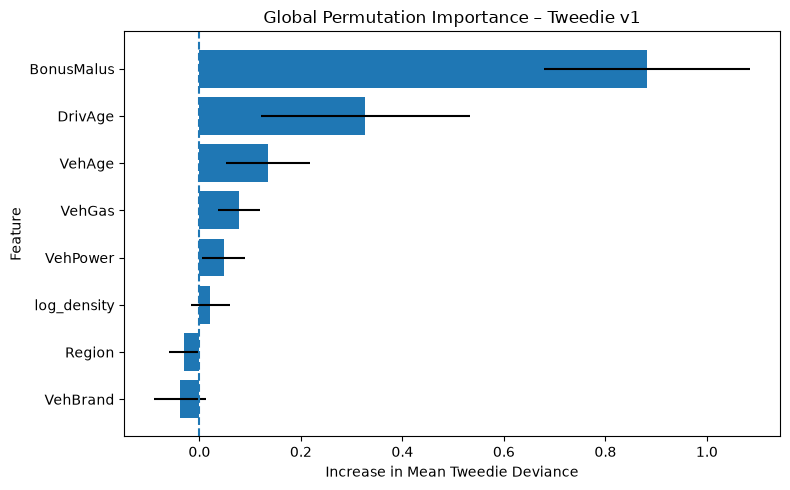

In [12]:
plt.figure(figsize=(8, 5))

plt.barh(
    tweedie_importance["feature"][::-1],
    tweedie_importance["importance_mean"][::-1],
    xerr=tweedie_importance["importance_std"][::-1],
)

plt.axvline(
    0,
    linestyle="--",
)

plt.xlabel("Increase in Mean Tweedie Deviance")
plt.ylabel("Feature")
plt.title("Global Permutation Importance – Tweedie v1")
plt.tight_layout()
plt.show()

### Ergebnis – Tweedie-Modell

Die globale Permutationsimportance des Tweedie-Modells zeigt `BonusMalus` als deutlich wichtigsten Prädiktor für die direkte Pure-Premium-Prognose.

`DrivAge` und `VehAge` folgen mit klar positiven Beiträgen, wobei insbesondere bei `DrivAge` eine erhöhte Streuung zwischen den Permutationswiederholungen sichtbar ist. `VehGas` und `VehPower` liefern kleinere zusätzliche Informationsbeiträge.

Für `Region` und `VehBrand` ergeben sich leicht negative mittlere Importance-Werte. Dies weist darauf hin, dass ihr zusätzlicher Informationsbeitrag im Holdout-Bestand nicht stabil nachweisbar ist.

Insgesamt zeigt das Tweedie-Modell damit ein klareres globales Importance-Muster als das Severity-Modell. Die numerischen Importance-Werte verschiedener Modelle werden jedoch nicht direkt miteinander verglichen, da unterschiedliche Zielgrößen und Deviance-Skalen verwendet werden.

## Partial Dependence und ICE

Zur Interpretation der Wirkungsrichtung werden Partial-Dependence- und ICE-Analysen verwendet.

Die Partial Dependence beschreibt den durchschnittlichen Zusammenhang zwischen einem Merkmal und der Modellprognose, während ICE-Kurven zeigen, wie sich dieser Zusammenhang für einzelne Policen unterscheiden kann.

Die Analysen sind modellbasierte Interpretationen und dürfen nicht als kausale Effekte verstanden werden.

In [13]:
frequency_numeric_pdp_features = [
    "BonusMalus",
    "VehAge",
    "DrivAge",
]

X_frequency_test[
    frequency_numeric_pdp_features
] = X_frequency_test[
    frequency_numeric_pdp_features
].astype(float)

print(
    X_frequency_test[
        frequency_numeric_pdp_features
    ].dtypes
)

BonusMalus    float64
VehAge        float64
DrivAge       float64
dtype: object


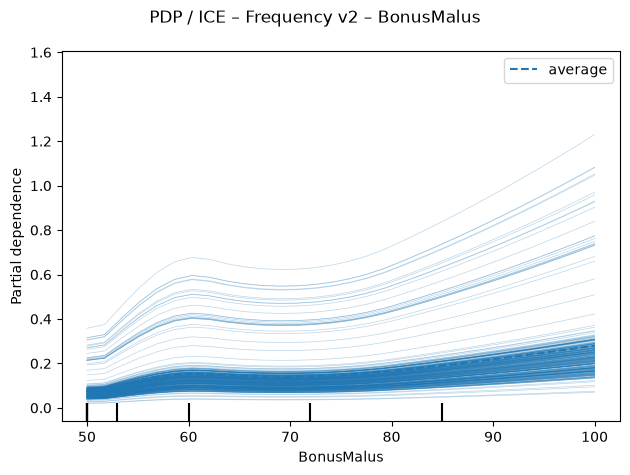

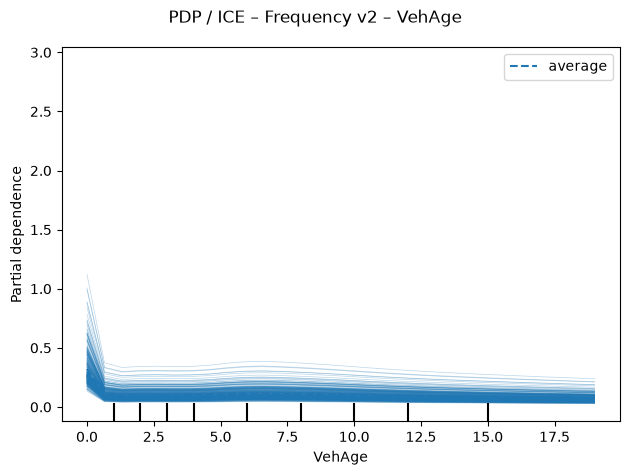

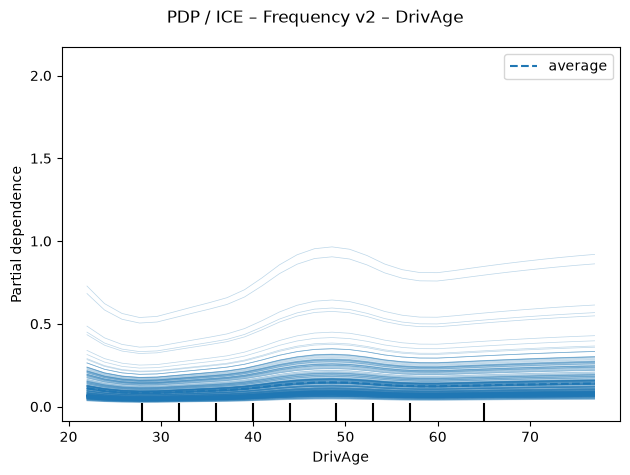

In [14]:
from sklearn.inspection import (
    PartialDependenceDisplay,
    partial_dependence,
)

frequency_pdp_features = [
    "BonusMalus",
    "VehAge",
    "DrivAge",
]

for feature in frequency_pdp_features:
    PartialDependenceDisplay.from_estimator(
        frequency_model,
        X_frequency_test,
        features=[feature],
        kind="both",
        subsample=300,
        random_state=42,
        grid_resolution=30,
        percentiles=(0.02, 0.98),
    )

    plt.suptitle(
        f"PDP / ICE – Frequency v2 – {feature}"
    )
    plt.tight_layout()
    plt.show()

In [15]:
frequency_pdp_tables = {}

for feature in frequency_pdp_features:
    result = partial_dependence(
        frequency_model,
        X_frequency_test,
        features=[feature],
        kind="average",
        grid_resolution=15,
        percentiles=(0.02, 0.98),
    )

    table = pd.DataFrame({
        feature: result["grid_values"][0],
        "predicted_frequency": result["average"][0],
    })

    frequency_pdp_tables[feature] = table

    print(f"\n{feature}")
    display(table)


BonusMalus


,BonusMalus,predicted_frequency
0,50.000000,0.081569
1,53.571429,0.106242
2,57.142857,0.140694
3,60.714286,0.154252
4,64.285714,0.146566
5,67.857143,0.142092
6,71.428571,0.142605
7,75.000000,0.148157
8,78.571429,0.159344
9,82.142857,0.176190



VehAge


,VehAge,predicted_frequency
0,0.000000,0.321685
1,1.357143,0.096095
2,2.714286,0.098916
3,4.071429,0.098981
4,5.428571,0.107380
5,6.785714,0.110436
6,8.142857,0.106013
7,9.500000,0.100139
8,10.857143,0.093579
9,12.214286,0.087905



DrivAge


,DrivAge,predicted_frequency
0,22.000000,0.110424
1,25.928571,0.084883
2,29.857143,0.083132
3,33.785714,0.092025
4,37.714286,0.101535
5,41.642857,0.122502
6,45.571429,0.141933
7,49.500000,0.145714
8,53.428571,0.133740
9,57.357143,0.123487


### Ergebnis – PDP / ICE des Frequency-Modells

Die Partial-Dependence-Analysen zeigen für die wichtigsten numerischen Merkmale des Frequency-Modells deutlich nichtlineare Zusammenhänge.

Für `BonusMalus` steigt die prognostizierte Schadenfrequenz insgesamt deutlich an. Nach einem ersten Anstieg bis etwa 60 Punkten folgt ein leicht abgeflachter Bereich, bevor die vorhergesagte Frequenz ab ungefähr 75 Punkten erneut deutlich zunimmt. Zwischen `BonusMalus = 50` und `100` steigt die durchschnittliche Prognose von rund 0,082 auf 0,280.

Bei `VehAge` zeigt sich ein besonders ausgeprägter Effekt für sehr neue Fahrzeuge. Für Fahrzeuge mit einem Alter von null Jahren liegt die durchschnittliche prognostizierte Schadenfrequenz bei rund 0,322 und fällt bereits innerhalb der ersten ein bis zwei Jahre stark ab. Nach einem kleinen Zwischenanstieg im mittleren Fahrzeugalter sinkt die Frequenz mit zunehmendem Fahrzeugalter schrittweise weiter.

Auch `DrivAge` weist einen nichtlinearen Verlauf auf. Die niedrigsten durchschnittlichen Frequenzprognosen liegen ungefähr im Bereich von 26 bis 30 Jahren. Anschließend steigt die prognostizierte Schadenfrequenz bis etwa 45–50 Jahre deutlich an, fällt danach zunächst wieder etwas ab und nimmt im höheren Alter erneut moderat zu.

Die ICE-Kurven zeigen zusätzlich Unterschiede im Prognoseniveau zwischen einzelnen Policen. Die grundlegenden Verlaufsformen bleiben jedoch erkennbar. Die dargestellten Zusammenhänge beschreiben Modellwirkungen und dürfen nicht als kausale Effekte interpretiert werden.

In [16]:
tweedie_pdp_features = [
    "BonusMalus",
    "DrivAge",
    "VehAge",
]

In [17]:
X_tweedie_pdp = X_tweedie_test.copy()

X_tweedie_pdp[
    tweedie_pdp_features
] = X_tweedie_pdp[
    tweedie_pdp_features
].astype(float)

print(
    X_tweedie_pdp[
        tweedie_pdp_features
    ].dtypes
)

BonusMalus    float64
DrivAge       float64
VehAge        float64
dtype: object


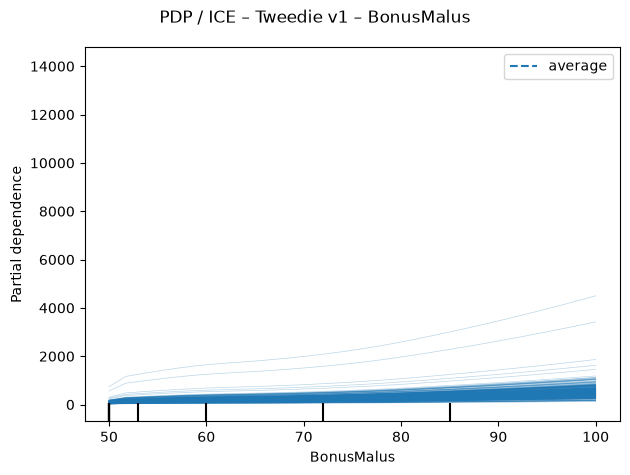

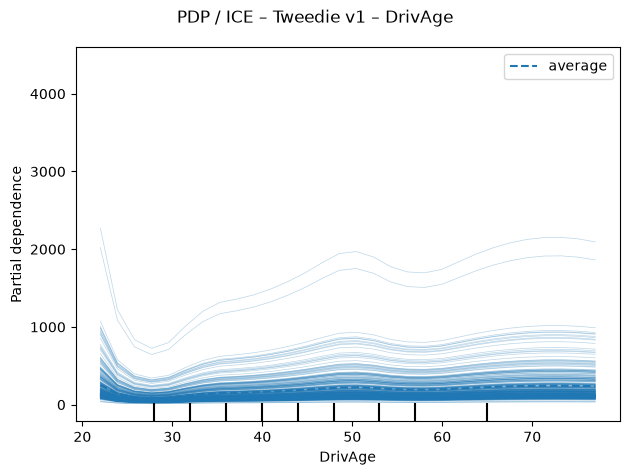

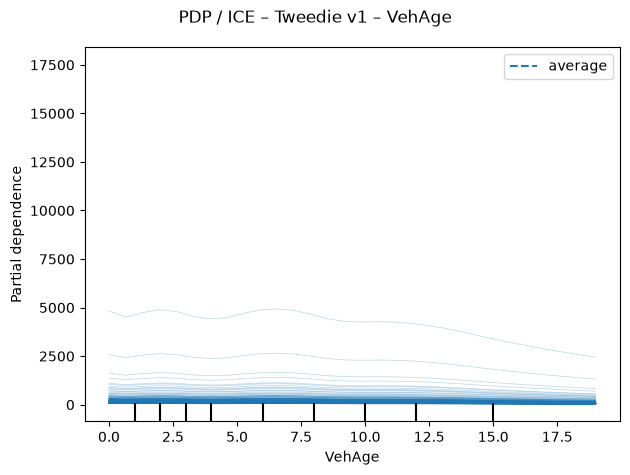

In [18]:
for feature in tweedie_pdp_features:
    PartialDependenceDisplay.from_estimator(
        tweedie_model,
        X_tweedie_pdp,
        features=[feature],
        kind="both",
        subsample=300,
        random_state=42,
        grid_resolution=30,
        percentiles=(0.02, 0.98),
    )

    plt.suptitle(
        f"PDP / ICE – Tweedie v1 – {feature}"
    )
    plt.tight_layout()
    plt.show()

In [19]:
tweedie_pdp_tables = {}

for feature in tweedie_pdp_features:
    result = partial_dependence(
        tweedie_model,
        X_tweedie_pdp,
        features=[feature],
        kind="average",
        grid_resolution=15,
        percentiles=(0.02, 0.98),
    )

    table = pd.DataFrame({
        feature: result["grid_values"][0],
        "predicted_pure_premium": result["average"][0],
    })

    tweedie_pdp_tables[feature] = table

    print(f"\n{feature}")
    display(table)


BonusMalus


,BonusMalus,predicted_pure_premium
0,50.000000,93.670220
1,53.571429,163.828308
2,57.142857,191.739168
3,60.714286,212.369661
4,64.285714,225.626368
5,67.857143,241.261404
6,71.428571,260.759020
7,75.000000,284.868432
8,78.571429,314.559498
9,82.142857,350.185223



DrivAge


,DrivAge,predicted_pure_premium
0,22.000000,257.292549
1,25.928571,92.937929
2,29.857143,93.459187
3,33.785714,139.506222
4,37.714286,155.388060
5,41.642857,172.280690
6,45.571429,198.174938
7,49.500000,222.943472
8,53.428571,206.679651
9,57.357143,191.791419



VehAge


,VehAge,predicted_pure_premium
0,0.000000,210.809410
1,1.357143,208.000236
2,2.714286,208.777365
3,4.071429,192.975067
4,5.428571,208.176654
5,6.785714,215.013338
6,8.142857,198.972142
7,9.500000,186.353553
8,10.857143,186.523885
9,12.214286,180.228536


### Ergebnis – PDP / ICE des Tweedie-Modells

Die Partial-Dependence-Analysen des Tweedie-Modells zeigen für die wichtigsten numerischen Merkmale klare und deutlich nichtlineare Wirkungsstrukturen.

Für `BonusMalus` ergibt sich ein stark und nahezu durchgehend ansteigender Zusammenhang mit der prognostizierten Pure Premium. Zwischen `BonusMalus = 50` und `100` steigt die durchschnittliche Modellprognose von rund 93,7 auf 570,8. Damit bestätigt die PDP-Analyse die herausragende globale Bedeutung dieses Merkmals.

`DrivAge` zeigt einen ausgeprägt nichtlinearen Verlauf. Für sehr junge Fahrer liegt die durchschnittliche prognostizierte Pure Premium zunächst auf einem hohen Niveau von rund 257. Im Bereich von etwa 26 bis 30 Jahren fällt sie auf rund 93 und erreicht damit ein lokales Minimum. Anschließend steigt die Prognose bis etwa 50 Jahre auf rund 223 an. Nach einem zwischenzeitlichen Rückgang im Bereich um 55 bis 60 Jahre nimmt die prognostizierte Pure Premium im höheren Alter erneut zu und erreicht Anfang der Siebzigerjahre Werte von über 240.

Auch `VehAge` weist keinen rein linearen Zusammenhang auf. Für sehr neue Fahrzeuge liegt die durchschnittliche Pure-Premium-Prognose zunächst bei rund 208 bis 211. Nach kleineren Schwankungen im unteren und mittleren Fahrzeugalter zeigt sich ab ungefähr 8 bis 10 Jahren ein zunehmend klarer Rückgang. Bei einem Fahrzeugalter von 19 Jahren beträgt die durchschnittliche Prognose nur noch rund 107.

Die ICE-Kurven zeigen zusätzlich deutliche Unterschiede im absoluten Prognoseniveau einzelner Policen. Die grundlegenden Verlaufsformen bleiben jedoch über viele Beobachtungen hinweg erkennbar. Die dargestellten Zusammenhänge sind modellbasierte Interpretationen und dürfen nicht als kausale Effekte verstanden werden.